# 05 — Drift-correction spin-up: prototype on one column

**Why.** The deep ice the boreholes sample is almost entirely spin-up state. Brute-force cycling
needs thousands of years on thick glaciers (settling time grows with thickness²), so 200 cycles
leave ~0.5 °C on Grenz/Gorner. Plan: `development_history/plans/2026-09-24_thermal_spinup_plan.md`.

**The idea in one sentence.** Run a few real years, measure how fast each layer is still
drifting, compute the temperature jump that cancels that drift, add it, and repeat until the
real model no longer drifts.

**What this notebook shows**

1. A Python copy of one IDL column: the same grid (1/5/20 m blocks), 3 × 10-day implicit steps
   per month, surface = min(0, air temperature), the geothermal ghost node at the bed, the
   melting-point clamp and the upwind vertical advection with its 0.8 Courant cap.
2. The exact equilibrium for comparison (solved directly, no long run needed).
3. The drift correction on seven test columns, including a melting base, strong emergence and
   seasonal snow that the jump does not know about.
4. Why the melting point needs special handling (a failure we hit, and its fix).
5. The relative-depth coordinate: the consistent burial speed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import solve_banded

SEC_YR = 365.25 * 86400.
DT = 86400. * 30. / 3.          # rf_dt: 10-day substep, 3 per month -> 360-day model year
K_ICE, C_ICE = 2.1, 1.9e6       # W/m/K, J/m3/K
G = 0.06                        # geothermal flux, W/m2
BOOK_FIG = Path('../development_history/figures')


def grid(H):
    """The model grid cut at the node nearest the thickness (IDL: tt = ind + 1)."""
    dz = np.concatenate([np.full(10, 1.), np.full(10, 5.), np.full(23, 20.)])
    z = np.concatenate([[0.], np.cumsum(dz[1:])])
    tt = int(np.argmin(np.abs(z - H))) + 1
    return z[:tt], dz[:tt]


class Column:
    """One band's temperature column, stepping exactly like firnice_temperature_model.pro."""

    def __init__(self, H, Tmean=-8., Tamp=10., w_surf=0., snow=False):
        self.z, self.dz = grid(H)
        self.n = len(self.z)
        self.snow = snow
        self.Tair = Tmean + Tamp * np.cos(2 * np.pi * (np.arange(12) - 6.5) / 12)
        self.w = w_surf * (1 - np.arange(self.n) / (self.n - 1))   # IDL: linear in layer index
        self.pmp = (self.z * 0.9 / 10.) * (-0.00742)
        self.dz_bed = max(self.z[-1] - self.z[-2], 1.)
        self.ra, self.rc, self.ab = self._coef(K_ICE)
        self.ra_snow, self.rc_snow, self.ab_snow = self._coef(0.35)

    def _coef(self, k_top):
        """Implicit finite-volume coefficients; k_top in the top 3 m (snow)."""
        n, dz = self.n, self.dz
        k = np.full(n, K_ICE); k[:4] = k_top
        ra = np.zeros(n - 2); rc = np.zeros(n - 2)
        for kk in range(n - 2):
            j = kk + 1
            dzm, dzp = dz[j], dz[min(j + 1, n - 1)]
            dzc = 0.5 * (dzm + dzp)
            ra[kk] = DT * 0.5 * (k[j - 1] + k[j]) / (C_ICE * dzc * dzm)
            rc[kk] = DT * 0.5 * (k[j] + k[min(j + 1, n - 1)]) / (C_ICE * dzc * dzp)
        ab = np.zeros((3, n - 2)); ab[0, 1:] = -rc[:-1]; ab[1] = 1 + ra + rc; ab[2, :-1] = -ra[1:]
        return ra, rc, ab

    def substep(self, T, Ts, m):
        n = self.n
        T = T.copy()
        snowy = self.snow and m in (11, 0, 1, 2, 3)                  # Dec-Apr snow cover
        ra, rc, ab = (self.ra_snow, self.rc_snow, self.ab_snow) if snowy else (self.ra, self.rc, self.ab)
        T[0] = min(0., Ts)
        T[-1] = min(T[-2] + G * self.dz_bed / K_ICE, self.pmp[-1])  # geothermal ghost node
        d = T[1:-1].copy(); d[0] += ra[0] * T[0]; d[-1] += rc[-1] * T[-1]
        T[1:-1] = np.minimum(solve_banded((1, 1), ab, d), self.pmp[1:-1])
        if np.max(np.abs(self.w)) > 0.1:                              # upwind vertical advection
            tv = T.copy(); dty = DT / SEC_YR
            for j in range(1, n - 1):
                dzz = (self.z[j] - self.z[j - 1]) if self.w[j] >= 0 else (self.z[j + 1] - self.z[j])
                c = np.clip(self.w[j] * dty / max(dzz, 1e-3), -0.8, 0.8)
                if c >= 0 and j > 1:
                    tv[j] -= c * (tv[j] - tv[j - 1])
                elif c < 0 and j < n - 2:
                    tv[j] -= c * (tv[j + 1] - tv[j])
            T[1:-1] = np.minimum(tv[1:-1], self.pmp[1:-1])
        return T

    def year(self, T):
        for m in range(12):
            for _ in range(3):
                T = self.substep(T, self.Tair[m], m)
        return T

    def L_matrix(self, bed_at_pmp=False):
        """The jump operator: annual-mean conduction + advection, rates per year.
        Surface change 0; bed follows its neighbour (fixed flux) unless the bed is at the
        melting point, where it is fixed (change 0)."""
        n, ni = self.n, self.n - 2
        L = np.zeros((ni, ni)); per_yr = SEC_YR / DT
        for k in range(ni):
            a, c = self.ra[k] * per_yr, self.rc[k] * per_yr
            L[k, k] -= a + c
            if k > 0: L[k, k - 1] += a
            if k < ni - 1: L[k, k + 1] += c
            elif not bed_at_pmp: L[k, k] += c
        if np.max(np.abs(self.w)) > 0.1:
            for k in range(ni):
                j = k + 1
                if self.w[j] >= 0 and j > 1:
                    r = self.w[j] / (self.z[j] - self.z[j - 1]); L[k, k] -= r; L[k, k - 1] += r
                elif self.w[j] < 0 and j < n - 2:
                    r = -self.w[j] / (self.z[j + 1] - self.z[j]); L[k, k] -= r; L[k, k + 1] += r
        return L

    def exact_cycle(self, iters=6):
        """Exact repeating state (start of year): Newton on the one-year map, by brute
        differentiation. Only for checking; far too expensive for production."""
        n = self.n
        T = np.full(n, self.Tair.mean())
        for _ in range(iters):
            F = self.year(T) - T
            J = np.zeros((n - 2, n - 2))
            for k in range(n - 2):
                Tp = T.copy(); Tp[k + 1] += 1e-4
                J[:, k] = ((self.year(Tp) - Tp) - F)[1:-1] / 1e-4
            T[1:-1] -= np.linalg.solve(J, F[1:-1])
        return self.year(T)

## The jump, and the three rules around it

After a few real years, the drift **D** (°C per year, per layer) is measured over one year.
The jump **δ** solves

$$ L\,\delta = -D $$

where **L** says how fast conduction and burial/emergence would move the column if it were
shifted by δ. It uses the model's own coefficients, averaged over the year.

Three rules keep the jump honest:

| rule | why |
|---|---|
| surface: δ = 0 | the climate sets the surface temperature |
| a layer cannot jump past the melting point; one already at it and still being warmed is held there | the real model clamps it every step, so it does not take part in the slow settling |
| if the bed is at the melting point, it is held fixed (instead of fixed heat flux) | the real model clamps the bed node; basal melting then absorbs the geothermal heat |

The second rule is an *active set*: solve, hold the layers that would pass the melting point,
solve again, release any held layer the rest of the column would pull colder, until nothing
changes. With ≤ 43 layers this takes a few tiny solves.

In [2]:
def constrained_jump(L, D, T, pmp, max_iter=50):
    """Solve L delta = -D with T + delta <= pmp (active set)."""
    ni = len(D)
    held = (T >= pmp - 1e-6) & (D >= -1e-6)      # at the melting point and not cooling
    for _ in range(max_iter):
        delta = np.zeros(ni)
        delta[held] = pmp[held] - T[held]
        f = ~held
        if f.any():
            rhs = -D[f] - L[np.ix_(f, held)] @ delta[held]
            delta[f] = np.linalg.solve(L[np.ix_(f, f)], rhs)
        pull = L[held] @ delta + D[held]            # < 0: column would pull it colder
        new = held.copy()
        new[f] = (T[f] + delta[f]) > pmp[f] + 1e-9
        new[np.where(held)[0][pull < 0]] = False
        if np.array_equal(new, held):
            return delta
        held = new
    return delta


def naive_jump(L, D, T, pmp):
    """The first version: plain linear solve, clamped afterwards."""
    return np.linalg.solve(L, -D)


def drift_spinup(col, T0, warm=5, block=3, tol=0.01, max_jumps=8, ref=None,
                 jump=constrained_jump, bed_switch=True):
    """warm real years; then repeat: measure one-year drift, jump, run block-1 more years.
    Stop after >= 2 jumps once the largest jump is below tol."""
    ops = {False: col.L_matrix(False), True: col.L_matrix(True)}
    T = T0.copy(); years = 0; hist = [(0, np.max(np.abs(T - ref)[1:]))] if ref is not None else []
    for _ in range(warm):
        T = col.year(T); years += 1
        if ref is not None: hist.append((years, np.max(np.abs(T - ref)[1:])))
    n_jumps = 0
    while n_jumps < max_jumps:
        T1 = col.year(T); years += 1
        D = (T1 - T)[1:-1] * (SEC_YR / (360 * 86400.))
        T = T1
        bed_hot = bool(bed_switch and T[-2] + G * col.dz_bed / K_ICE >= col.pmp[-1])
        delta = jump(ops[bed_hot], D, T[1:-1], col.pmp[1:-1])
        T[1:-1] = np.minimum(T[1:-1] + delta, col.pmp[1:-1])
        T[-1] = min(T[-2] + G * col.dz_bed / K_ICE, col.pmp[-1])
        n_jumps += 1
        if ref is not None: hist.append((years, np.max(np.abs(T - ref)[1:])))
        for _ in range(block - 1):
            T = col.year(T); years += 1
            if ref is not None: hist.append((years, np.max(np.abs(T - ref)[1:])))
        if n_jumps >= 2 and np.max(np.abs(delta)) < tol:
            return T, years, n_jumps, True, hist
    return T, years, n_jumps, False, hist


def brute(col, T0, nyears, ref):
    T = T0.copy(); err = [np.max(np.abs(T - ref)[1:])]
    for _ in range(nyears):
        T = col.year(T); err.append(np.max(np.abs(T - ref)[1:]))
    return T, np.array(err)

## Seven test columns

Thickness 259 m is typical of the Grenz/Gorner trunk; 139 m with a warm climate reaches the
melting point at the bed; 39 m is a small glacier. Burial +1 m/yr is an accumulation area,
emergence −3 m/yr a steep tongue. "Seasonal snow" drops the conductivity of the top 3 m to
0.35 W/m/K from December to April in the *real* model, while the jump keeps using ice: a test of
how forgiving the jump is when it does not know the physics exactly.

Error = largest difference to the exact equilibrium over all layers below the surface.

In [3]:
CASES = {
    'cold 259 m, no flow':                 dict(H=259, Tmean=-8., Tamp=10.),
    'cold 259 m, burial +1 m/yr':          dict(H=259, Tmean=-8., Tamp=10., w_surf=1.),
    'cold 259 m, emergence -3 m/yr':       dict(H=259, Tmean=-8., Tamp=10., w_surf=-3.),
    'warm 139 m, melting base':            dict(H=139, Tmean=-1.5, Tamp=8.),
    'small 39 m':                          dict(H=39, Tmean=-4., Tamp=9.),
    'cold 259 m, emergence, seasonal snow': dict(H=259, Tmean=-8., Tamp=10., w_surf=-3., snow=True),
    'cold 259 m, no flow, seasonal snow':  dict(H=259, Tmean=-8., Tamp=10., snow=True),
}
rows, runs = [], {}
for name, kw in CASES.items():
    col = Column(**kw)
    T0 = np.full(col.n, col.Tair.mean())
    ref = col.exact_cycle()
    _, eb = brute(col, T0, 3000, ref)
    T, yrs, nj, ok, hist = drift_spinup(col, T0, ref=ref)
    Tv = T.copy()
    for _ in range(50):
        Tv = col.year(Tv)
    runs[name] = (eb, hist)
    rows.append({'case': name, 'bed at pmp': ref[-1] >= col.pmp[-1] - 1e-9,
                 'brute 200 yr err': eb[200], 'brute 3000 yr err': eb[3000],
                 'drift: years': yrs, 'jumps': nj, 'converged': ok,
                 'drift err': np.max(np.abs(T - ref)[1:]),
                 '50 more yr move (>=15 m)': np.max(np.abs(Tv - T)[col.z >= 15])})
res = pd.DataFrame(rows).set_index('case')
res.round(4)

,bed at pmp,brute 200 yr err,brute 3000 yr err,drift: years,jumps,converged,drift err,50 more yr move (>=15 m)
case,,,,,,,,
"cold 259 m, no flow",False,4.1760,0.0894,11,2,True,0.0003,0.0002
"cold 259 m, burial +1 m/yr",False,1.7672,0.0014,11,2,True,0.0002,0.0002
"cold 259 m, emergence -3 m/yr",True,6.1659,0.0000,14,3,True,0.0001,0.0001
"warm 139 m, melting base",True,0.0037,0.0000,17,4,True,0.0000,0.0000
small 39 m,False,0.0000,0.0000,11,2,True,0.0003,0.0003
"cold 259 m, emergence, seasonal snow",True,6.2957,0.0000,17,4,True,0.0001,0.0001
"cold 259 m, no flow, seasonal snow",True,4.9634,0.0000,17,4,True,0.0001,0.0001


**How to read it.** The drift correction lands within ~0.001 °C of the exact equilibrium in
11–17 simulated years, every case, whatever the thickness. Brute force needs far longer. Fifty
extra plain years after the drift correction move nothing below 15 m, which is the check that the
result is the real model's own equilibrium.

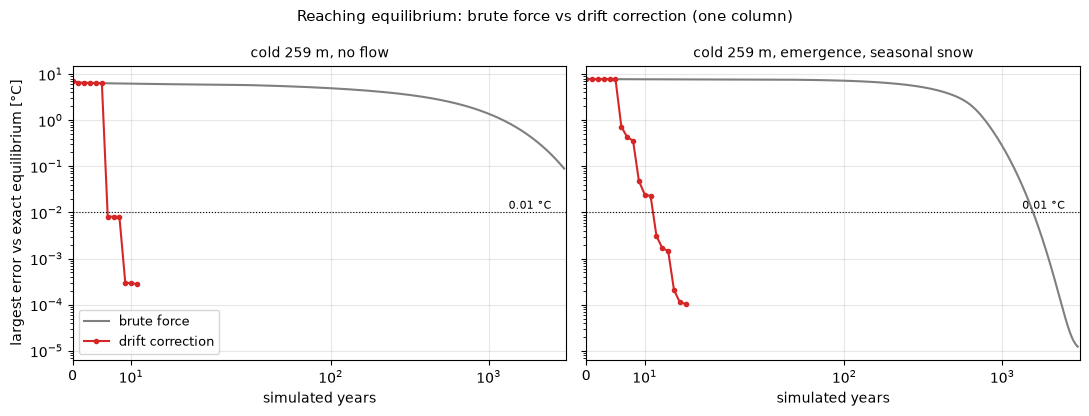

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, ['cold 259 m, no flow', 'cold 259 m, emergence, seasonal snow']):
    eb, hist = runs[name]
    ax.semilogy(np.arange(len(eb)), eb + 1e-5, color='tab:gray', label='brute force')
    y, e = zip(*hist)
    ax.semilogy(y, np.array(e) + 1e-5, 'o-', color='tab:red', ms=3, label='drift correction')
    ax.axhline(0.01, color='k', ls=':', lw=.8)
    ax.text(2500, 0.012, '0.01 °C', fontsize=8, ha='right')
    ax.set_xscale('symlog', linthresh=30)
    ax.set_xlim(0, 3100)
    ax.set_xlabel('simulated years')
    ax.set_title(name, fontsize=10)
    ax.grid(alpha=.3)
axes[0].set_ylabel('largest error vs exact equilibrium [°C]')
axes[0].legend(fontsize=9)
fig.suptitle('Reaching equilibrium: brute force vs drift correction (one column)', fontsize=11)
fig.tight_layout()
fig.savefig(BOOK_FIG / 'ch05_drift_vs_bruteforce.svg')   # book figure, chapter 5

## Why the melting point needs special handling

The first version solved the jump as a plain straight-line prediction and clamped at the melting
point afterwards. It works on cold columns and fails badly once any ice reaches the melting
point:

In [5]:
comp = []
for name in ['cold 259 m, no flow', 'cold 259 m, emergence -3 m/yr', 'warm 139 m, melting base']:
    col = Column(**CASES[name]); T0 = np.full(col.n, col.Tair.mean()); ref = col.exact_cycle()
    for label, kw in [('first version', dict(jump=naive_jump, bed_switch=False)),
                      ('limit only', dict(bed_switch=False)),
                      ('limit + bed switch', {})]:
        T, yrs, nj, ok, _ = drift_spinup(col, T0, ref=ref, **kw)
        comp.append({'case': name, 'jump': label, 'converged': ok, 'years': yrs,
                     'error': np.max(np.abs(T - ref)[1:])})
pd.DataFrame(comp).set_index(['case', 'jump']).round(3)

converged  years   error
case                          jump                                        
cold 259 m, no flow           first version            True     11   0.000
                              limit only               True     11   0.000
                              limit + bed switch       True     11   0.000
cold 259 m, emergence -3 m/yr first version           False     29  10.227
                              limit only              False     29   8.015
                              limit + bed switch       True     14   0.000
warm 139 m, melting base      first version           False     29   2.310
                              limit only              False     29   2.189
                              limit + bed switch       True     17   0.000

Two separate things go wrong:

1. **The jump does not know that ice cannot pass 0 °C.** From a cold start it predicts
   warming far beyond the melting point (up to +95 °C in the emergence case), the clamp cuts
   it off, and the next jump swings back: a loop. The fix is to build the limit into the jump.
2. **The bed behaves differently once it melts.** With a cold bed, the geothermal *flux* is fixed.
   A uniform warming of the whole column can then only escape at the surface, and under emergence
   it has to diffuse down against rising ice, which takes ~9000 years. The jump reads a drift of
   0.001 °C/yr as "8 °C still to go". Once the bed reaches the melting point, the real model
   holds its *temperature* fixed and the extra heat melts ice, so that slow mode is gone. The
   jump must switch its bed condition to match.

With both, every case converges.

## Relative depth: the consistent burial speed

Horizontal advection will take ice from the band upglacier at the same **relative depth**
ζ = depth / thickness (instead of the same absolute depth), because ice flows roughly parallel
to the bed. The vertical motion must then be measured on the same ζ levels, or part of it is
counted twice or not at all.

**Derivation in words.** In steady state, the ice a band gains at the surface each year (the
surface balance *b*, ice equivalent) leaves downglacier as ice flux. Of the ice passing
level ζ, the fraction *F(ζ)* of the flux above ζ has already been carried away horizontally
by the time we reach ζ. So the ice still moving *down through* level ζ is

$$ w_\zeta(\zeta) = b\,\bigl(1 - F(\zeta)\bigr), \qquad F(\zeta) = \int_0^\zeta \frac{u(\zeta')}{\bar u}\,d\zeta' $$

with the Nye shape the model already uses, $u(\zeta)/\bar u = (1-\zeta^4)/0.8$. Checks:
at the surface $w_\zeta = b$ (burial equals the surface balance), and at the bed $F(1)=1$,
so $w_\zeta = 0$ (no ice crosses the bed). In the ablation area *b* < 0 and the same formula
gives emergence. In firn, the burial speed in metres of firn is larger by ρ_ice/ρ(z).

The current code uses $b(1-\zeta)$, which is correct only for plug flow (u the same at all
depths). With the Nye shape more of the flux is near the surface, so burial slows faster with
depth:

F(1) = 1.0000  (must be 1: all the flux is accounted for)
w at surface 1.000 b,  at bed 0.0000 b


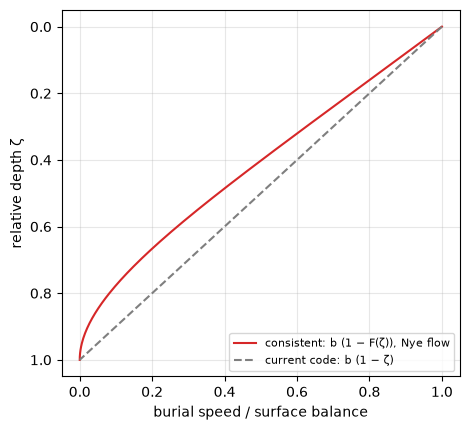

In [6]:
zeta = np.linspace(0, 1, 201)
u_shape = (1 - zeta**4) / 0.8
F = np.concatenate([[0.], np.cumsum(0.5 * (u_shape[1:] + u_shape[:-1]) * np.diff(zeta))])
w_nye = 1 - F
print(f'F(1) = {F[-1]:.4f}  (must be 1: all the flux is accounted for)')
print(f'w at surface {w_nye[0]:.3f} b,  at bed {w_nye[-1]:.4f} b')

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot(w_nye, zeta, color='tab:red', label='consistent: b (1 − F(ζ)), Nye flow')
ax.plot(1 - zeta, zeta, color='tab:gray', ls='--', label='current code: b (1 − ζ)')
ax.invert_yaxis(); ax.set_xlabel('burial speed / surface balance'); ax.set_ylabel('relative depth ζ')
ax.grid(alpha=.3); ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()

## What the IDL version must do

| step | detail |
|---|---|
| warm-up | 5 real years with the full model, all bands |
| measure | D = change over one real year, per layer, per band |
| operator | L from the band's own conduction and advection coefficients (three diagonals, so the existing Thomas solver works); bed condition switched when the bed node is clamped |
| along-glacier coupling | add H = u/dx (capped like the model) and solve bands from the top down, each using the jump of the band above |
| limit | active set on the melting point |
| stop | after ≥ 2 jumps, once every jump is < 0.01 °C; verify with 5 plain years; after 8 jumps without success fall back to plain cycling and flag it |
| validate | against the 3000-cycle brute-force reference (`truthref2_w0`), ≤ 0.02 °C everywhere |